# 5. EDA of station-day aggregated Citi Bike data

**Who worked on this:** Rune Lemmens

This notebook explores the aggregated output with descriptive statistics, correlations, coordinate, age, gender, and station usage plots. Run 04_aggregation.ipynb first.

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Standalone access to Section 6's aggregate output.
DATA_DIR = Path.cwd() / "data"
AGGREGATED_OUTPUT_PATH = DATA_DIR / "processed" / "citibike_station_day_summary_2013_2019.csv"
CHUNK_SIZE = 200_000
if not AGGREGATED_OUTPUT_PATH.exists():
    raise FileNotFoundError(f"Station-day aggregate CSV not found: {AGGREGATED_OUTPUT_PATH}. Run 04_aggregation.ipynb first.")

## 7. EDA of station-day aggregated data

The correlation matrix below is calculated from the aggregated CSV, where each row represents one start station on one calendar day. Station IDs, dates, coordinates, and weekday codes are identifiers or categories rather than continuous measures, so they are excluded. Pearson correlations are pairwise-complete and unweighted across station-day rows; count fields are related by construction, so correlations should be interpreted cautiously. Constant fields have undefined correlations and appear as `NA`.

In [9]:
import numpy as np

aggregate_describe_columns = [
    "trip_count", "mean_trip_duration_s", "min_trip_duration_s", "max_trip_duration_s",
    "member_trip_count", "casual_trip_count", "birth_year_known_count", "mean_birth_year",
    "gender_0_trip_count", "gender_1_trip_count", "gender_2_trip_count",
]
if not AGGREGATED_OUTPUT_PATH.exists():
    raise FileNotFoundError("Run Section 6 aggregation before describing aggregate metrics.")

# Accumulate count, mean, variance, min, and max incrementally to avoid loading the full CSV.
aggregate_stats = None
median_sample_parts = []
rows_seen = 0
for describe_chunk in pd.read_csv(
    AGGREGATED_OUTPUT_PATH,
    usecols=aggregate_describe_columns,
    chunksize=CHUNK_SIZE,
    low_memory=False,
):
    describe_chunk = describe_chunk.apply(pd.to_numeric, errors="coerce")
    chunk_count = describe_chunk.count()
    chunk_mean = describe_chunk.mean()
    chunk_m2 = describe_chunk.var(ddof=1).fillna(0) * (chunk_count - 1).clip(lower=0)
    chunk_stats = pd.DataFrame({
        "count": chunk_count,
        "mean": chunk_mean,
        "m2": chunk_m2,
        "min": describe_chunk.min(),
        "max": describe_chunk.max(),
    })

    if aggregate_stats is None:
        aggregate_stats = chunk_stats
    else:
        previous_count = aggregate_stats["count"]
        combined_count = previous_count + chunk_stats["count"]
        mean_delta = chunk_stats["mean"] - aggregate_stats["mean"]
        aggregate_stats["m2"] += (
            chunk_stats["m2"]
            + mean_delta.pow(2)
            * previous_count
            * chunk_stats["count"]
            / combined_count.replace(0, np.nan)
        )
        aggregate_stats["mean"] += mean_delta * chunk_stats["count"] / combined_count.replace(0, np.nan)
        aggregate_stats["count"] = combined_count
        aggregate_stats["min"] = pd.concat(
            [aggregate_stats["min"], chunk_stats["min"]], axis=1
        ).min(axis=1)
        aggregate_stats["max"] = pd.concat(
            [aggregate_stats["max"], chunk_stats["max"]], axis=1
        ).max(axis=1)

    # Keep a deterministic 1% sample for approximate medians; exact medians require full data in memory.
    row_positions = np.arange(len(describe_chunk)) + rows_seen
    sample_rows = describe_chunk.loc[row_positions % 100 == 0]
    if not sample_rows.empty:
        median_sample_parts.append(sample_rows)
    rows_seen += len(describe_chunk)

if aggregate_stats is None:
    raise ValueError("The aggregated CSV contains no rows to describe.")

aggregate_stats["std"] = np.sqrt(
    aggregate_stats["m2"] / (aggregate_stats["count"] - 1).replace(0, np.nan)
)
aggregate_medians = pd.concat(median_sample_parts, ignore_index=True).median()
aggregate_describe = aggregate_stats[["count", "mean", "std", "min", "max"]].copy()
aggregate_describe["median (1% sample)"] = aggregate_medians
aggregate_describe = aggregate_describe[[
    "count", "mean", "std", "min", "median (1% sample)", "max",
]]
print(f"Descriptive statistics across {rows_seen:,} station-day rows:")
display(aggregate_describe.T.round(2))

Descriptive statistics across 1,297,662 station-day rows:


,trip_count,mean_trip_duration_s,min_trip_duration_s,max_trip_duration_s,member_trip_count,casual_trip_count,birth_year_known_count,mean_birth_year,gender_0_trip_count,gender_1_trip_count,gender_2_trip_count
count,1297662.00,1297662.00,1297662.00,1297662.00,1297662.00,1297662.00,1297662.00,1297078.00,1297662.00,1297662.00,1297662.00
mean,70.78,942.27,158.95,7921.48,62.24,8.54,65.99,1978.74,7.22,47.79,15.78
std,73.30,2067.39,1305.93,28963.87,65.15,17.06,69.44,4.09,14.14,52.07,16.39
min,1.00,61.00,60.00,61.00,0.00,0.00,0.00,1900.00,0.00,0.00,0.00
median (1% sample),45.00,783.91,123.00,2583.00,40.00,3.00,42.00,1978.68,3.00,30.00,10.00
max,1174.00,599420.00,599420.00,604548.00,921.00,581.00,1174.00,2003.00,572.00,824.00,366.00


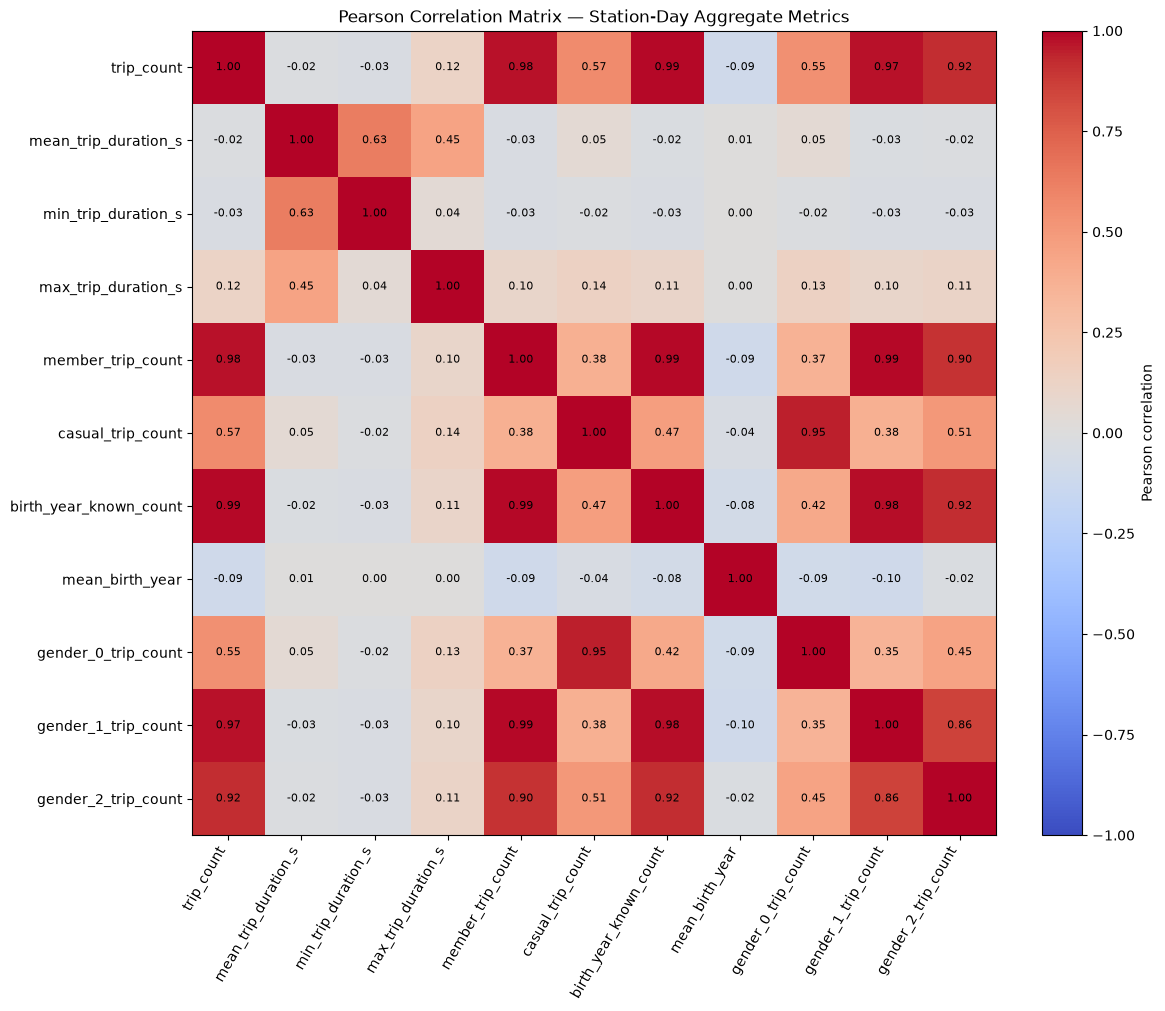

,trip_count,mean_trip_duration_s,min_trip_duration_s,max_trip_duration_s,member_trip_count,casual_trip_count,birth_year_known_count,mean_birth_year,gender_0_trip_count,gender_1_trip_count,gender_2_trip_count
trip_count,1.000000,-0.016366,-0.034361,0.118473,0.976451,0.567032,0.985158,-0.093859,0.545279,0.970303,0.919175
mean_trip_duration_s,-0.016366,1.000000,0.632286,0.446114,-0.031551,0.050168,-0.024447,0.007632,0.048361,-0.030387,-0.018360
min_trip_duration_s,-0.034361,0.632286,1.000000,0.039575,-0.034238,-0.016862,-0.034155,0.001837,-0.016699,-0.033092,-0.034129
max_trip_duration_s,0.118473,0.446114,0.039575,1.000000,0.096645,0.139869,0.107139,0.001506,0.134398,0.095054,0.111929
member_trip_count,0.976451,-0.031551,-0.034238,0.096645,1.000000,0.375977,0.985265,-0.094314,0.365462,0.991550,0.901445
casual_trip_count,0.567032,0.050168,-0.016862,0.139869,0.375977,1.000000,0.469630,-0.043042,0.946717,0.381832,0.506255
birth_year_known_count,0.985158,-0.024447,-0.034155,0.107139,0.985265,0.469630,1.000000,-0.077983,0.417253,0.983464,0.921407
mean_birth_year,-0.093859,0.007632,0.001837,0.001506,-0.094314,-0.043042,-0.077983,1.000000,-0.090178,-0.100166,-0.023722
gender_0_trip_count,0.545279,0.048361,-0.016699,0.134398,0.365462,0.946717,0.417253,-0.090178,1.000000,0.354238,0.450681
gender_1_trip_count,0.970303,-0.030387,-0.033092,0.095054,0.991550,0.381832,0.983464,-0.100166,0.354238,1.000000,0.856779


In [10]:
import numpy as np
import matplotlib.pyplot as plt

aggregate_correlation_columns = [
    "trip_count", "mean_trip_duration_s", "min_trip_duration_s", "max_trip_duration_s",
    "member_trip_count", "casual_trip_count", "birth_year_known_count", "mean_birth_year",
    "gender_0_trip_count", "gender_1_trip_count", "gender_2_trip_count",
]
if not AGGREGATED_OUTPUT_PATH.exists():
    raise FileNotFoundError("Run Section 6 aggregation before calculating aggregate correlations.")

aggregate_column_count = len(aggregate_correlation_columns)
pair_counts = np.zeros((aggregate_column_count, aggregate_column_count), dtype=np.int64)
pair_sum_x = np.zeros((aggregate_column_count, aggregate_column_count), dtype=np.float64)
pair_sum_x2 = np.zeros((aggregate_column_count, aggregate_column_count), dtype=np.float64)
pair_sum_xy = np.zeros((aggregate_column_count, aggregate_column_count), dtype=np.float64)

for correlation_chunk in pd.read_csv(
    AGGREGATED_OUTPUT_PATH,
    usecols=aggregate_correlation_columns,
    chunksize=CHUNK_SIZE,
    low_memory=False,
):
    values = correlation_chunk.apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64)
    valid = np.isfinite(values)
    mask = valid.astype(np.float64)
    filled = np.where(valid, values, 0.0)
    pair_counts += (mask.T @ mask).astype(np.int64)
    pair_sum_x += filled.T @ mask
    pair_sum_x2 += (filled * filled).T @ mask
    pair_sum_xy += filled.T @ filled

count_float = pair_counts.astype(np.float64)
with np.errstate(divide="ignore", invalid="ignore"):
    covariance_numerator = pair_sum_xy - (pair_sum_x * pair_sum_x.T) / count_float
    variance_x = pair_sum_x2 - (pair_sum_x * pair_sum_x) / count_float
    variance_y = variance_x.T
    denominator = np.sqrt(np.maximum(variance_x, 0) * np.maximum(variance_y, 0))
    aggregate_correlation_values = np.divide(
        covariance_numerator,
        denominator,
        out=np.full_like(covariance_numerator, np.nan),
        where=(count_float > 1) & (denominator > 0),
    )
aggregate_correlation_values = np.clip(aggregate_correlation_values, -1, 1)
aggregate_correlation_matrix = pd.DataFrame(
    aggregate_correlation_values,
    index=aggregate_correlation_columns,
    columns=aggregate_correlation_columns,
)

fig, ax = plt.subplots(figsize=(12, 10), constrained_layout=True)
image = ax.imshow(aggregate_correlation_matrix.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(aggregate_column_count), aggregate_correlation_columns, rotation=60, ha="right")
ax.set_yticks(range(aggregate_column_count), aggregate_correlation_columns)
ax.set_title("Pearson Correlation Matrix — Station-Day Aggregate Metrics")
for row in range(aggregate_column_count):
    for column in range(aggregate_column_count):
        value = aggregate_correlation_values[row, column]
        label = f"{value:.2f}" if np.isfinite(value) else "NA"
        ax.text(column, row, label, ha="center", va="center", color="black", fontsize=8)
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.show()
aggregate_correlation_matrix

### 7.2 Geographic spread of start-station coordinates

The station-day aggregate retains start-station latitude and longitude, but not end-station coordinates. This chunked scan plots one point per station, colored by its total trips across the period, to show the spatial coverage without overplotting one point per day.

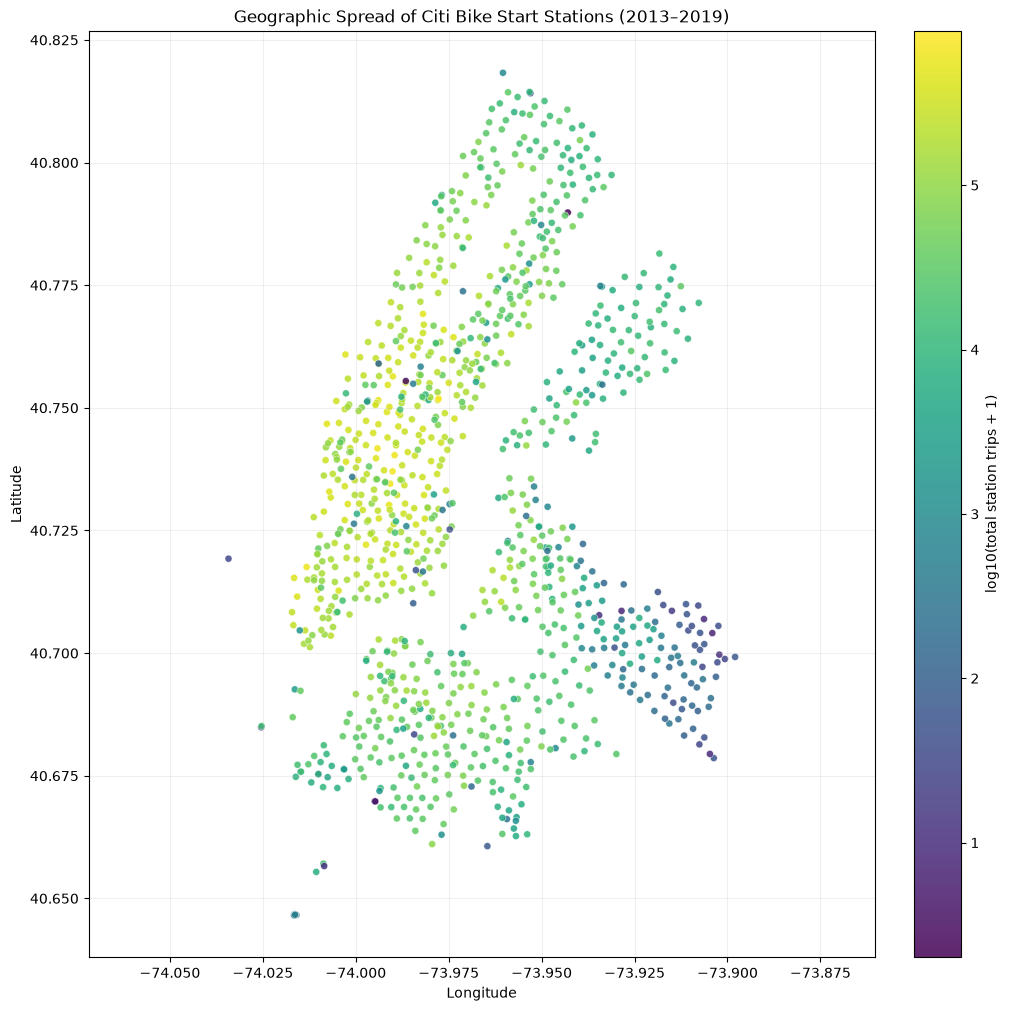

Distinct stations plotted: 1,060
Latitude range: 40.64654 to 40.81830; longitude range: -74.03423 to -73.89795


In [11]:
import matplotlib.pyplot as plt

coordinate_plot_columns = [
    "start_station_id", "start_lat", "start_lng", "trip_count",
]
if not AGGREGATED_OUTPUT_PATH.exists():
    raise FileNotFoundError("Run Section 6 aggregation before plotting station coordinates.")

station_locations = {}
for coordinate_chunk in pd.read_csv(
    AGGREGATED_OUTPUT_PATH,
    usecols=coordinate_plot_columns,
    chunksize=CHUNK_SIZE,
    low_memory=False,
):
    coordinate_chunk["start_lat"] = pd.to_numeric(coordinate_chunk["start_lat"], errors="coerce")
    coordinate_chunk["start_lng"] = pd.to_numeric(coordinate_chunk["start_lng"], errors="coerce")
    coordinate_chunk["trip_count"] = pd.to_numeric(coordinate_chunk["trip_count"], errors="coerce")
    coordinate_chunk = coordinate_chunk.dropna(
        subset=["start_station_id", "start_lat", "start_lng", "trip_count"]
    )

    station_chunk = coordinate_chunk.groupby("start_station_id", observed=True).agg(
        start_lat=("start_lat", "first"),
        start_lng=("start_lng", "first"),
        trip_total=("trip_count", "sum"),
    )
    for station_id, station in station_chunk.iterrows():
        if station_id not in station_locations:
            station_locations[station_id] = {
                "lat": float(station["start_lat"]),
                "lng": float(station["start_lng"]),
                "trips": 0.0,
            }
        station_locations[station_id]["trips"] += float(station["trip_total"])

if not station_locations:
    raise ValueError("No valid start-station coordinates were found in the aggregate output.")

station_latitudes = np.array([station["lat"] for station in station_locations.values()])
station_longitudes = np.array([station["lng"] for station in station_locations.values()])
station_trip_totals = np.array([station["trips"] for station in station_locations.values()])
log_station_trip_totals = np.log10(station_trip_totals + 1)
mean_latitude = float(station_latitudes.mean())

fig, ax = plt.subplots(figsize=(10, 10), constrained_layout=True)
points = ax.scatter(
    station_longitudes,
    station_latitudes,
    c=log_station_trip_totals,
    cmap="viridis",
    s=26,
    alpha=0.85,
    edgecolors="white",
    linewidths=0.35,
)
ax.set_title("Geographic Spread of Citi Bike Start Stations (2013–2019)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.deg2rad(mean_latitude)), adjustable="datalim")
ax.grid(alpha=0.2)
colorbar = fig.colorbar(points, ax=ax)
colorbar.set_label("log10(total station trips + 1)")
plt.show()

print(f"Distinct stations plotted: {len(station_locations):,}")
print(
    "Latitude range: "
    f"{station_latitudes.min():.5f} to {station_latitudes.max():.5f}; "
    "longitude range: "
    f"{station_longitudes.min():.5f} to {station_longitudes.max():.5f}"
)

### 7.3 Rider age distribution

Approximate rider age as `trip_year - birth_year` from the station-day aggregate. Since birth year is aggregated as a daily mean, this describes the age distribution of station-day mean birth years (not individual riders); weight each station-day by its `birth_year_known_count` to account for the number of trips with recorded birth year. Age is approximate because birthdays are unavailable.

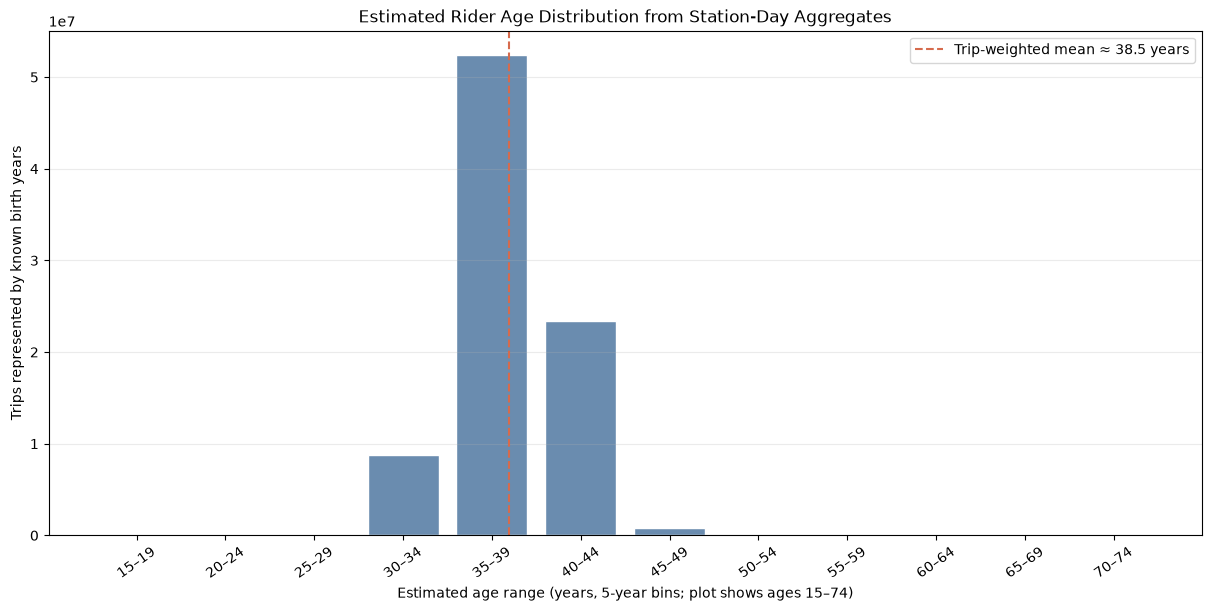

Known-birth-year trips represented: 85,633,484
Valid estimated ages outside the displayed 15–74 range: 30 (0.00%)
Trips with missing or out-of-range estimated ages excluded: 0
Note: ages are estimated from each station-day's mean birth year, then weighted by its known-birth-year trip count; this is not an exact individual-level age distribution.


In [12]:
import numpy as np
import matplotlib.pyplot as plt

age_plot_columns = ["trip_date", "birth_year_known_count", "mean_birth_year"]
if not AGGREGATED_OUTPUT_PATH.exists():
    raise FileNotFoundError("Run Section 6 aggregation before plotting age distribution.")

age_bin_edges = np.arange(0, 126, 5)
age_bin_trip_weights = np.zeros(len(age_bin_edges) - 1, dtype=np.float64)
valid_age_trip_weight = 0.0
invalid_age_trip_weight = 0.0
weighted_age_sum = 0.0

for age_chunk in pd.read_csv(
    AGGREGATED_OUTPUT_PATH,
    usecols=age_plot_columns,
    chunksize=CHUNK_SIZE,
    low_memory=False,
):
    trip_year = pd.to_datetime(age_chunk["trip_date"], errors="coerce").dt.year
    known_birth_years = pd.to_numeric(age_chunk["birth_year_known_count"], errors="coerce").fillna(0)
    mean_birth_year = pd.to_numeric(age_chunk["mean_birth_year"], errors="coerce")
    estimated_age = trip_year - mean_birth_year
    valid = estimated_age.notna() & known_birth_years.gt(0) & estimated_age.between(0, 120)

    valid_ages = estimated_age.loc[valid].to_numpy(dtype=np.float64)
    valid_weights = known_birth_years.loc[valid].to_numpy(dtype=np.float64)
    age_bin_trip_weights += np.histogram(
        valid_ages, bins=age_bin_edges, weights=valid_weights
    )[0]
    valid_age_trip_weight += float(valid_weights.sum())
    weighted_age_sum += float((valid_ages * valid_weights).sum())
    invalid_age_trip_weight += float(
        known_birth_years.loc[known_birth_years.gt(0) & ~valid].sum()
    )

if valid_age_trip_weight == 0:
    raise ValueError("No valid aggregated birth-year data was found for the age plot.")

weighted_mean_estimated_age = weighted_age_sum / valid_age_trip_weight
plot_min_age, plot_max_age = 15, 75
first_display_bin = int(np.searchsorted(age_bin_edges, plot_min_age))
last_display_bin = int(np.searchsorted(age_bin_edges, plot_max_age))
displayed_weights = age_bin_trip_weights[first_display_bin:last_display_bin]
displayed_edges = age_bin_edges[first_display_bin:last_display_bin + 1]
displayed_labels = [
    f"{int(lower)}–{int(upper - 1)}"
    for lower, upper in zip(displayed_edges[:-1], displayed_edges[1:])
]
excluded_plot_range_weight = valid_age_trip_weight - float(displayed_weights.sum())
mean_line_position = (weighted_mean_estimated_age - displayed_edges[0]) / 5 - 0.5

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
ax.bar(displayed_labels, displayed_weights, color="#6a8caf", edgecolor="white")
ax.set_title("Estimated Rider Age Distribution from Station-Day Aggregates")
ax.set_xlabel("Estimated age range (years, 5-year bins; plot shows ages 15–74)")
ax.set_ylabel("Trips represented by known birth years")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)
ax.axvline(
    mean_line_position,
    color="#d66b4d",
    linestyle="--",
    linewidth=1.5,
    label=f"Trip-weighted mean ≈ {weighted_mean_estimated_age:.1f} years",
)
ax.legend()
plt.show()

print(f"Known-birth-year trips represented: {valid_age_trip_weight:,.0f}")
print(
    f"Valid estimated ages outside the displayed 15–74 range: "
    f"{excluded_plot_range_weight:,.0f} ({excluded_plot_range_weight / valid_age_trip_weight:.2%})"
)
print(f"Trips with missing or out-of-range estimated ages excluded: {invalid_age_trip_weight:,.0f}")
print(
    "Note: ages are estimated from each station-day's mean birth year, "
    "then weighted by its known-birth-year trip count; this is not an exact individual-level age distribution."
)

### 7.4 Recorded gender-code distribution

Sum the trip counts for each recorded gender code across station-day rows. In these historical Citi Bike files, `0` means unknown/not reported, `1` male, and `2` female. The chart shows the distribution of recorded codes, not gender identity beyond the dataset's limited categories.

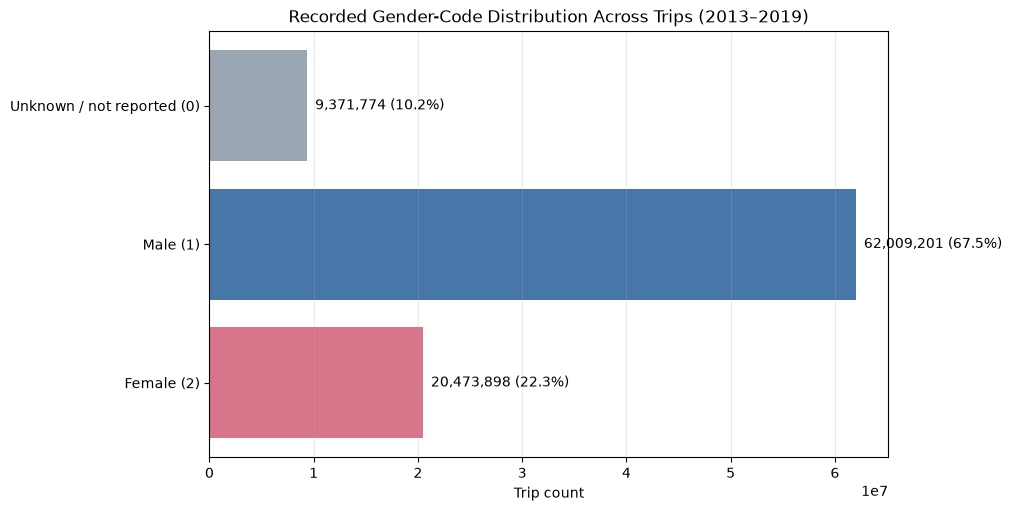

Trips with a recorded gender code: 91,854,873


In [13]:
import matplotlib.pyplot as plt

_gender_columns = ["gender_0_trip_count", "gender_1_trip_count", "gender_2_trip_count"]
if not AGGREGATED_OUTPUT_PATH.exists():
    raise FileNotFoundError("Run Section 6 aggregation before plotting gender-code counts.")

_gender_totals = pd.Series(0, index=_gender_columns, dtype="int64")
for _gender_chunk in pd.read_csv(
    AGGREGATED_OUTPUT_PATH,
    usecols=_gender_columns,
    chunksize=CHUNK_SIZE,
    low_memory=False,
):
    _gender_totals += _gender_chunk.apply(pd.to_numeric, errors="coerce").sum().astype("int64")

_gender_labels = ["Unknown / not reported (0)", "Male (1)", "Female (2)"]
_gender_counts = _gender_totals.to_numpy(dtype=np.int64)
_gender_total = int(_gender_counts.sum())
if _gender_total == 0:
    raise ValueError("No recorded gender-code counts were found in the aggregate CSV.")
_gender_percentages = _gender_counts / _gender_total * 100

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
_gender_bars = ax.barh(_gender_labels, _gender_counts, color=["#9aa6b2", "#4776a8", "#d8758a"])
ax.invert_yaxis()
ax.set_title("Recorded Gender-Code Distribution Across Trips (2013–2019)")
ax.set_xlabel("Trip count")
ax.grid(axis="x", alpha=0.25)
for _bar, _count, _percentage in zip(_gender_bars, _gender_counts, _gender_percentages):
    ax.text(
        _bar.get_width(),
        _bar.get_y() + _bar.get_height() / 2,
        f"  {_count:,.0f} ({_percentage:.1f}%)",
        va="center",
        ha="left",
    )
plt.show()

print(f"Trips with a recorded gender code: {_gender_total:,}")

### 7.5 Station usage spread and top 10 station locations

Sum station-day trip counts across the full 2013–2019 period to show how usage is distributed across distinct start-station IDs. The section reports the ten busiest stations and overlays them in a contrasting color on the all-station coordinate map, matching the geographic view in Section 7.2. Numbered markers correspond to the ranked table. A log-scaled histogram makes the long-tailed station usage easier to inspect.

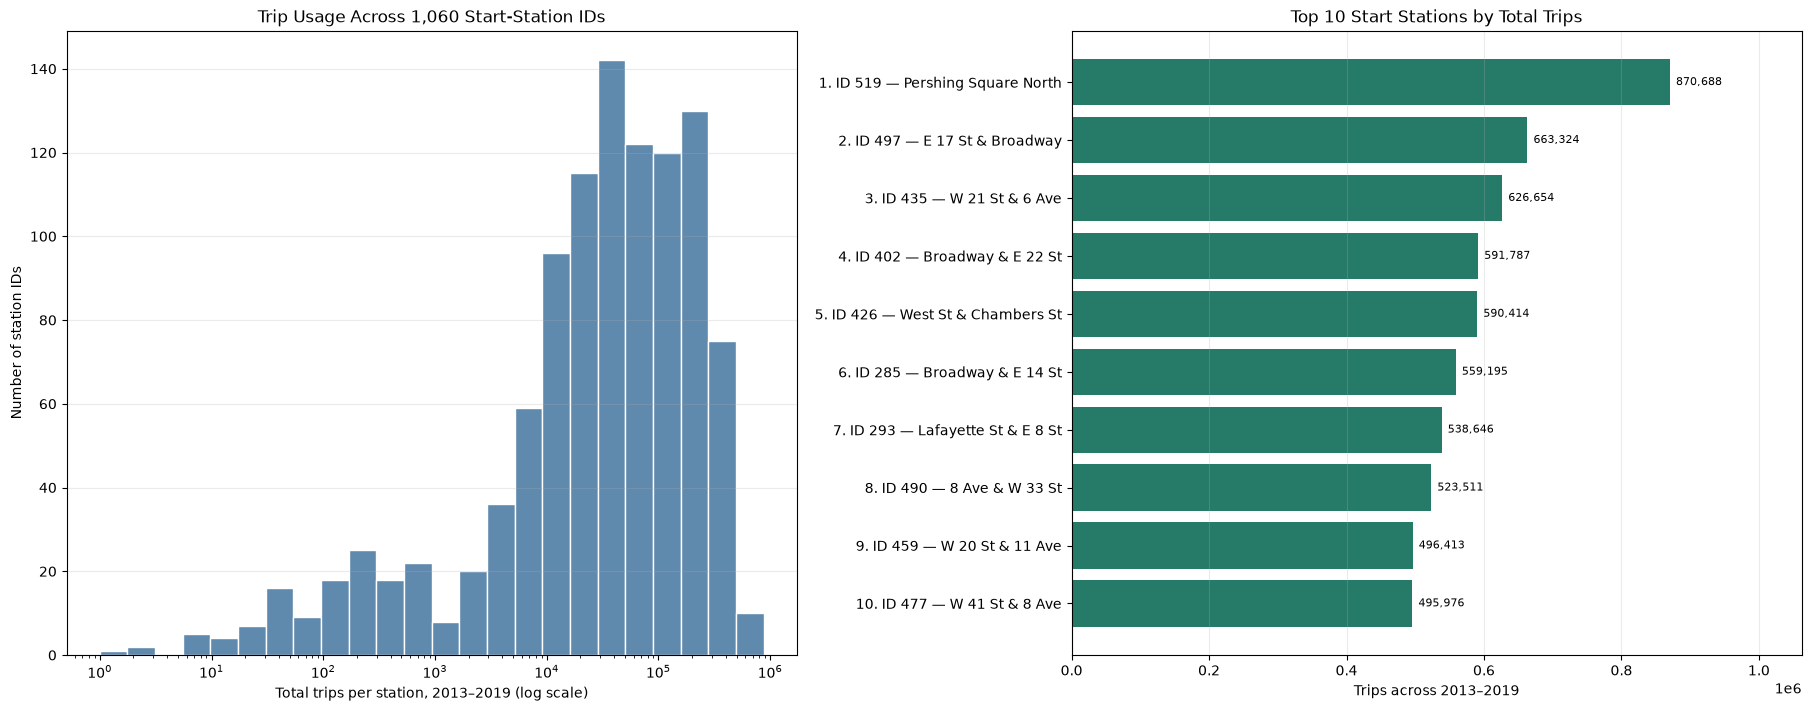

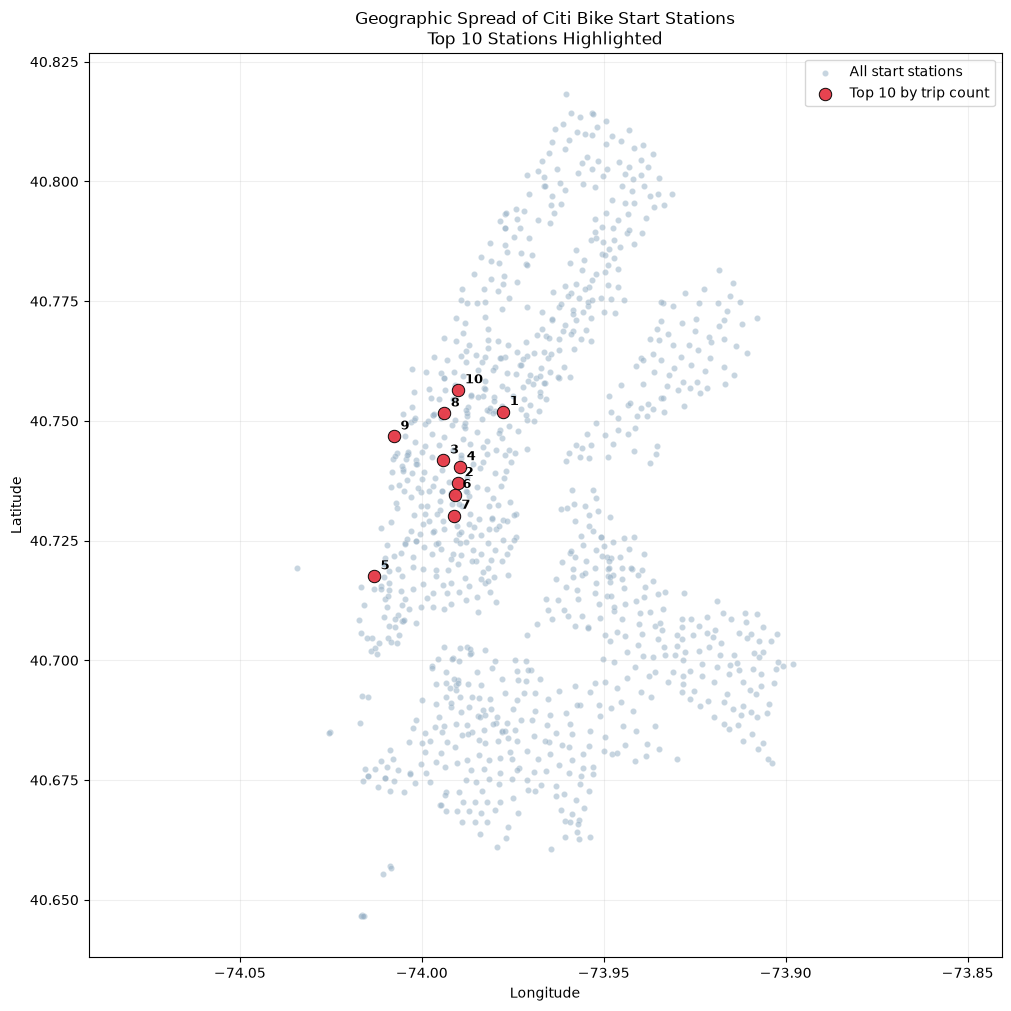

Distinct start-station IDs: 1,060
Top 10 start stations (map numbers match the Rank column):


,station_id,station_name,trips_2013_2019,latitude,longitude
rank,,,,,
1,519,Pershing Square North,870688,40.751873,-73.977706
2,497,E 17 St & Broadway,663324,40.737050,-73.990093
3,435,W 21 St & 6 Ave,626654,40.741740,-73.994156
4,402,Broadway & E 22 St,591787,40.740343,-73.989551
5,426,West St & Chambers St,590414,40.717548,-74.013221
6,285,Broadway & E 14 St,559195,40.734546,-73.990741
7,293,Lafayette St & E 8 St,538646,40.730207,-73.991026
8,490,8 Ave & W 33 St,523511,40.751551,-73.993934
9,459,W 20 St & 11 Ave,496413,40.746745,-74.007756


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_station_columns = [
    "start_station_id", "start_station_name", "start_lat", "start_lng", "trip_count",
]
if not AGGREGATED_OUTPUT_PATH.exists():
    raise FileNotFoundError("Run Section 6 aggregation before summarizing station usage.")

_station_totals_by_id = {}
for _station_chunk in pd.read_csv(
    AGGREGATED_OUTPUT_PATH,
    usecols=_station_columns,
    chunksize=CHUNK_SIZE,
    low_memory=False,
):
    _station_chunk["start_lat"] = pd.to_numeric(_station_chunk["start_lat"], errors="coerce")
    _station_chunk["start_lng"] = pd.to_numeric(_station_chunk["start_lng"], errors="coerce")
    _station_chunk["trip_count"] = pd.to_numeric(_station_chunk["trip_count"], errors="coerce")
    _station_chunk = _station_chunk.dropna(subset=["start_station_id", "trip_count"])

    _grouped_stations = _station_chunk.groupby("start_station_id", observed=True, sort=False).agg(
        station_name=("start_station_name", "first"),
        latitude=("start_lat", "first"),
        longitude=("start_lng", "first"),
        total_trips=("trip_count", "sum"),
    )
    for _station_id, _station in _grouped_stations.iterrows():
        _saved_station = _station_totals_by_id.setdefault(_station_id, {
            "station_name": _station["station_name"],
            "latitude": _station["latitude"],
            "longitude": _station["longitude"],
            "total_trips": 0,
        })
        if pd.isna(_saved_station["station_name"]) and pd.notna(_station["station_name"]):
            _saved_station["station_name"] = _station["station_name"]
        if pd.isna(_saved_station["latitude"]) and pd.notna(_station["latitude"]):
            _saved_station["latitude"] = float(_station["latitude"])
        if pd.isna(_saved_station["longitude"]) and pd.notna(_station["longitude"]):
            _saved_station["longitude"] = float(_station["longitude"])
        _saved_station["total_trips"] += int(_station["total_trips"])

if not _station_totals_by_id:
    raise ValueError("No start-station IDs were found in the aggregate output.")

_station_usage = pd.DataFrame.from_dict(_station_totals_by_id, orient="index")
_station_usage.index.name = "station_id"
_station_usage = _station_usage.reset_index()
_station_usage["station_id"] = _station_usage["station_id"].map(
    lambda value: str(int(float(value)))
    if pd.notna(value) and str(value).replace(".", "", 1).isdigit() and float(value).is_integer()
    else str(value).strip()
)
_station_usage = _station_usage.sort_values("total_trips", ascending=False).reset_index(drop=True)
_station_usage["rank"] = np.arange(1, len(_station_usage) + 1)
_top_10_stations = _station_usage.head(10).copy()

# Overall spread: one value per distinct station ID, shown on a logarithmic trip-count axis.
_positive_station_trips = _station_usage.loc[_station_usage["total_trips"] > 0, "total_trips"]
_histogram_bins = np.geomspace(
    max(1, float(_positive_station_trips.min())),
    float(_positive_station_trips.max()) * 1.001,
    25,
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)
axes[0].hist(_positive_station_trips, bins=_histogram_bins, color="#5f89ad", edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_title(f"Trip Usage Across {len(_station_usage):,} Start-Station IDs")
axes[0].set_xlabel("Total trips per station, 2013–2019 (log scale)")
axes[0].set_ylabel("Number of station IDs")
axes[0].grid(axis="y", alpha=0.25)

_top_labels = [
    f"{int(row.rank)}. ID {row.station_id} — "
    f"{str(row.station_name)[:26] if pd.notna(row.station_name) else 'Unnamed'}"
    for row in _top_10_stations.itertuples()
]
_top_bars = axes[1].barh(
    _top_labels[::-1],
    _top_10_stations["total_trips"].to_numpy()[::-1],
    color="#267a68",
)
axes[1].set_title("Top 10 Start Stations by Total Trips")
axes[1].set_xlabel("Trips across 2013–2019")
axes[1].set_xlim(0, float(_top_10_stations["total_trips"].max()) * 1.22)
axes[1].grid(axis="x", alpha=0.25)
for _bar in _top_bars:
    axes[1].text(
        _bar.get_width() + float(_top_10_stations["total_trips"].max()) * 0.01,
        _bar.get_y() + _bar.get_height() / 2,
        f"{_bar.get_width():,.0f}",
        va="center",
        ha="left",
        fontsize=8,
    )
plt.show()

# Match the Section 7.2 geographic overview and highlight the top ten in a contrasting color.
_all_station_locations = _station_usage.dropna(subset=["latitude", "longitude"]).copy()
_top_10_mappable = _top_10_stations.dropna(subset=["latitude", "longitude"]).copy()
if _all_station_locations.empty:
    print("Station locations cannot be mapped: no station coordinates are available.")
else:
    _all_latitudes = _all_station_locations["latitude"].to_numpy(dtype=float)
    _all_longitudes = _all_station_locations["longitude"].to_numpy(dtype=float)
    _map_mean_latitude = float(_all_latitudes.mean())

    fig, ax = plt.subplots(figsize=(10, 10), constrained_layout=True)
    ax.scatter(
        _all_longitudes,
        _all_latitudes,
        color="#9ab3c8",
        s=20,
        alpha=0.55,
        edgecolors="white",
        linewidths=0.25,
        label="All start stations",
        zorder=1,
    )
    if not _top_10_mappable.empty:
        ax.scatter(
            _top_10_mappable["longitude"],
            _top_10_mappable["latitude"],
            color="#e63946",
            s=80,
            alpha=0.95,
            edgecolors="black",
            linewidths=0.7,
            label="Top 10 by trip count",
            zorder=3,
        )
        for _mapped_station in _top_10_mappable.itertuples():
            ax.annotate(
                str(int(_mapped_station.rank)),
                (_mapped_station.longitude, _mapped_station.latitude),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=9,
                weight="bold",
                zorder=4,
            )
    ax.set_title("Geographic Spread of Citi Bike Start Stations\nTop 10 Stations Highlighted")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect(1 / np.cos(np.deg2rad(_map_mean_latitude)), adjustable="datalim")
    ax.grid(alpha=0.2)
    ax.legend(loc="best")
    plt.show()

print(f"Distinct start-station IDs: {len(_station_usage):,}")
print("Top 10 start stations (map numbers match the Rank column):")
display(
    _top_10_stations[["rank", "station_id", "station_name", "total_trips", "latitude", "longitude"]]
    .rename(columns={"total_trips": "trips_2013_2019"})
    .set_index("rank")
)